<a href="https://www.kaggle.com/code/lourdesgarcagarfias/3b-ritmo-cinc2017-ipynb?scriptVersionId=374132092" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

# Clasificación de ritmos con CinC 2017

**Proyecto #7 · Detección de arritmias en tiempo real con TinyML**

**2** Clasificación de ritmos: Utilizaré CinC 2017, pues es útil para este enfoque de una sola derivación porque se quiere identificar si una ventana de señal presenta FA u otro ritmo.
Es decir, que dado un tramo de ECG de una sola derivación, queremos buscar qué ritmo se tiene?

### ¿Por qué CinC 2017?
- Es de **una sola derivación**, igual que el AD8232.
- Viene de un aparato portátil y barato (AliveCor), con ruido real.
- Cada registro (9–60 s) es una ventanacon una etiqueta de ritmo:

| Etiqueta | Significa |
|---|---|
| `N` | ritmo normal |
| `A` | fibrilación auricular (FA) |
| `O` | otro ritmo anormal (no FA) |
| `~` | demasiado ruidoso para decidir |

### Flujo

| Notebook de seguros | Este notebook |
|---|---|
| Cada fila = un cliente | Cada fila = **un registro (una ventana)** |
| Columnas: edad, salario... | Columnas: medidas de los **intervalos R–R** y de la **calidad de la señal** |
| Objetivo: ¿cobró? | Objetivo: ¿**N**, **A**, **O** o **~**? |
| Dummy vs kNN | Dummy vs regla simple vs kNN |
| F1 y matriz de confusión | F1 **por clase** y matriz de confusión |


| Lo que buscamos | En este notebook |
|---|---|
| **Etiquetas** | Las de CinC 2017 (versión corregida v3) |
| **Métricas** | F1 por clase (la métrica oficial del reto) y, para FA, Se, Sp y PPV |
| **Validación** | Validación cruzada de 5 grupos (ver la advertencia en la sección 6) |

## 0. Antes de empezar

1. Pon este notebook en la **misma carpeta** que `ecg_comun.py` (ahí está el detector de picos R).
2. Corre la celda de abajo **una vez** para instalar las librerías.
3. La primera vez se descargan ~100 MB a la carpeta `datos/`.

In [1]:
%pip install -q wfdb numpy pandas scipy matplotlib seaborn scikit-learn 

Note: you may need to restart the kernel to use updated packages.


In [2]:
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.dummy import DummyClassifier
from sklearn.metrics import confusion_matrix, f1_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

import sys, glob, os
ruta_ecg = glob.glob("/kaggle/input/**/ecg_comun.py", recursive=True)[0]
RUTA = os.path.dirname(ruta_ecg)
print("Mis archivos están en:", RUTA)
sys.path.append(RUTA)                # para que no haya problema encontrando ecg_comun.py
os.makedirs("datos", exist_ok=True)
if not os.path.exists("datos/cinc2017"):
    os.symlink(RUTA, "datos/cinc2017")  
import ecg_comun as ec

DATOS = Path("datos")
plt.rcParams["figure.figsize"] = (12, 3.5)
plt.rcParams["axes.grid"] = True

ec.descargar_cinc2017(DATOS / "cinc2017")

Mis archivos están en: /kaggle/input/datasets/lourdesgarcagarfias/cinc2017-proyecto7/cinc2017-proyecto7
[ok] CinC 2017: ya está descargada en datos/cinc2017


## 1. Decisiones de este notebook

Todas juntas para que las cambies y vuelvas a correr. Debes poder justificar cada una.

In [3]:
RR_MIN, RR_MAX = 0.25, 2.5   # R–R fuera de este rango (s) = artefacto
MIN_LATIDOS = 8              # registros con menos latidos válidos no se pueden medir
K_VECINOS = 15
N_GRUPOS = 5                 # grupos de la validación cruzada
SEMILLA = 42
CLASES = ["N", "A", "O", "~"]
NOMBRE_CLASE = {"N": "Normal", "A": "FA", "O": "Otro ritmo", "~": "Ruidoso"}

---
# PARTE A · Exploración

## A.1 ¿Cuántos registros hay de cada ritmo? 

,ritmo,registros,%
N,Normal,5076,59.5
A,FA,758,8.9
O,Otro ritmo,2415,28.3
~,Ruidoso,279,3.3


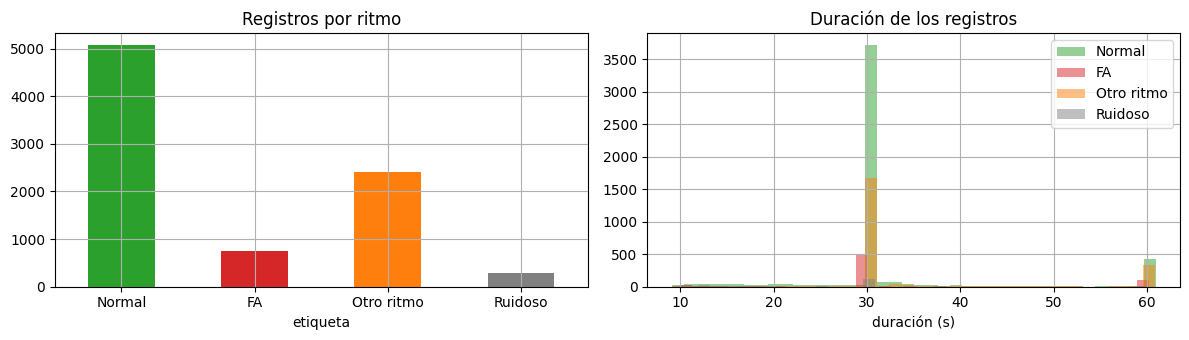

In [4]:
cinc = ec.leer_etiquetas_cinc2017(DATOS / "cinc2017")
duraciones = []
for ruta in cinc.ruta:
    campos = Path(ruta).with_suffix(".hea").read_text().split()
    duraciones.append(int(campos[3]) / float(campos[2]))      # muestras / frecuencia = segundos
cinc["duracion_s"] = duraciones

conteo = cinc.etiqueta.value_counts().reindex(CLASES)
display(pd.DataFrame({"ritmo": [NOMBRE_CLASE[c] for c in CLASES], "registros": conteo.values,
                      "%": (100 * conteo / conteo.sum()).round(1).values}, index=CLASES))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
conteo.rename(NOMBRE_CLASE).plot.bar(ax=ax[0], color=["tab:green", "tab:red", "tab:orange", "gray"])
ax[0].set_title("Registros por ritmo"); ax[0].tick_params(axis="x", rotation=0)
for c, color in zip(CLASES, ["tab:green", "tab:red", "tab:orange", "gray"]):
    ax[1].hist(cinc[cinc.etiqueta == c].duracion_s, bins=40, alpha=0.5, color=color, label=NOMBRE_CLASE[c])
ax[1].set_xlabel("duración (s)"); ax[1].set_title("Duración de los registros"); ax[1].legend()
plt.tight_layout(); plt.show()

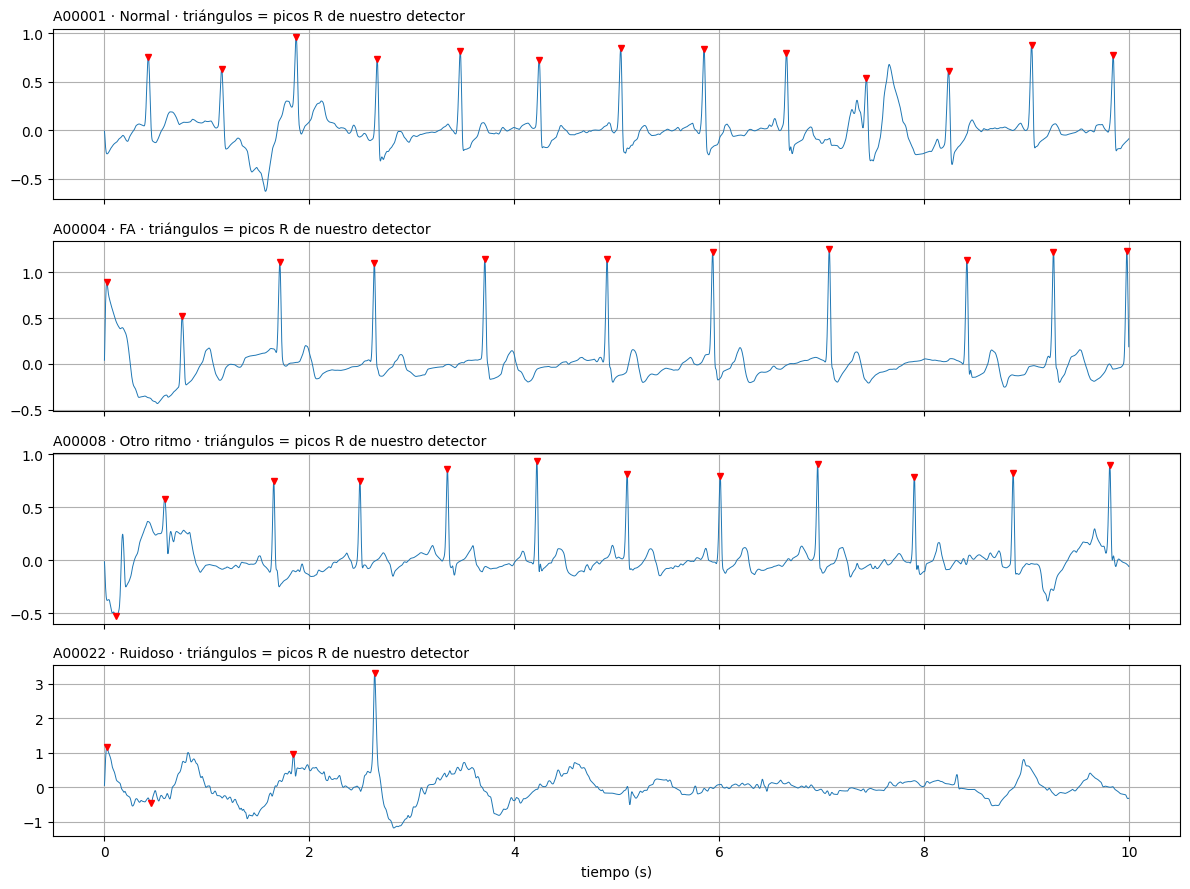

In [5]:
fig, ax = plt.subplots(4, 1, figsize=(12, 9), sharex=True)
for eje, c in zip(ax, CLASES):
    fila = cinc[cinc.etiqueta == c].iloc[0]
    x, fs = ec.leer_senal_cinc2017(fila.ruta)
    x = ec.remuestrear(x, fs, ec.FS)   
    limpia = ec.filtrar(x, ec.FS)
    r = ec.detectar_picos_r(x, ec.FS)
    n = min(len(limpia), 10 * ec.FS)
    eje.plot(np.arange(n) / ec.FS, limpia[:n], lw=0.7)
    rr = r[r < n]
    eje.plot(rr / ec.FS, limpia[rr], "rv", ms=5)
    eje.set_title(f"{fila.registro} · {NOMBRE_CLASE[c]} · triángulos = picos R de nuestro detector", loc="left", fontsize=10)
ax[-1].set_xlabel("tiempo (s)")
plt.tight_layout(); plt.show()

** NOTAS **
- **Normal:** picos R igual de espaciados, con onda P antes de cada QRS.
- **FA:** picos R **desordenados** y sin onda P.
- **Otro ritmo:** puede ser cualquier cosa anormal que no sea FA (extrasístoles frecuentes, taquicardia, bloqueos...). Por eso es la clase **más difícil**.
- **Ruidoso:** la señal está tan sucia que hasta el detector de R se equivoca.

# PARTE B · De señal a tabla

## B.1 Las medidas de cada registro

Cada registro se convierte en **una fila con 10 números**. Hay dos grupos:

**a) Desorden de los R–R** (para distinguir FA):

| Medida | Qué mide | En FA... |
|---|---|---|
| `fc` | frecuencia cardiaca promedio (lpm) | suele subir |
| `cv` | desviación estándar ÷ promedio de los R–R | **sube** |
| `rmssd_n` | cuánto cambia cada R–R respecto al anterior (normalizado) | **sube** |
| `pnn50` | fracción de cambios entre R–R consecutivos > 50 ms | **sube** |
| `madn` | dispersión "robusta" de los R–R (ignora valores raros) | **sube** |
| `tpr` | fracción de puntos de giro (sube-baja-sube) | se acerca a 2/3, como algo al azar |

**b) Calidad de la señal y de la detección** (para distinguir **ruido**):

| Medida | Qué mide | En registros ruidosos... |
|---|---|---|
| `frac_rr_raros` | fracción de R–R fuera del rango posible | **sube** (el detector se confunde) |
| `cv_amplitud_r` | qué tanto cambia la altura de los picos R | **sube** |
| `latidos_por_s` | latidos detectados por segundo | puede ser absurda |
| `ruido_alto` | fracción de la energía por arriba de 40 Hz | **sube** |


In [6]:
NOMBRES_RR = ["fc", "cv", "rmssd_n", "pnn50", "madn", "tpr"]
NOMBRES_CALIDAD = ["frac_rr_raros", "cv_amplitud_r", "latidos_por_s", "ruido_alto"]
NOMBRES = NOMBRES_RR + NOMBRES_CALIDAD

def medidas_registro(x, fs):
    x = ec.remuestrear(x, fs, ec.FS)
    limpia = ec.filtrar(x, ec.FS)
    r = ec.detectar_picos_r(x, ec.FS)
    dur = len(x) / ec.FS
    rr_todos = np.diff(r) / ec.FS
    rr = rr_todos[(rr_todos > RR_MIN) & (rr_todos < RR_MAX)]

    # b) calidad
    frac_raros = 1 - len(rr) / max(len(rr_todos), 1)
    amp = np.abs(limpia[r]) if len(r) else np.array([0.0])
    cv_amp = amp.std() / (amp.mean() + 1e-9)
    espectro = np.abs(np.fft.rfft(x - x.mean())) ** 2
    frec = np.fft.rfftfreq(len(x), 1 / ec.FS)
    ruido_alto = espectro[frec > 40].sum() / (espectro[frec > 0.5].sum() + 1e-12)
    calidad = [frac_raros, cv_amp, len(r) / dur, ruido_alto]

    # a) desorden de los R–R
    if len(rr) < MIN_LATIDOS:
        return [np.nan] * len(NOMBRES_RR) + calidad
    d = np.diff(rr)
    giros = np.sum((rr[1:-1] - rr[:-2]) * (rr[1:-1] - rr[2:]) > 0)
    desorden = [60 / rr.mean(), rr.std() / rr.mean(), np.sqrt(np.mean(d ** 2)) / rr.mean(),
                np.mean(np.abs(d) > 0.05), np.median(np.abs(rr - np.median(rr))) / np.median(rr),
                giros / max(len(rr) - 2, 1)]
    return desorden + calidad

## B.2 Calcular las medidas de los ~8,500 registros

In [7]:
filas = []
for i, fila in enumerate(cinc.itertuples()):
    x, fs = ec.leer_senal_cinc2017(fila.ruta)
    filas.append(medidas_registro(x, fs))
    if (i + 1) % 1000 == 0:
        print(f"  {i + 1} de {len(cinc)} registros...")
tabla = pd.concat([cinc[["registro", "etiqueta", "duracion_s"]], pd.DataFrame(filas, columns=NOMBRES)], axis=1)

sin_rr = tabla[NOMBRES_RR].isna().any(axis=1)
print(f"\nRegistros donde no se pudieron medir los R–R: {sin_rr.sum()}")
display(tabla[sin_rr].etiqueta.value_counts().rename("registros sin medidas de R–R"))
display(tabla.head())

  1000 de 8528 registros...
  2000 de 8528 registros...
  3000 de 8528 registros...
  4000 de 8528 registros...
  5000 de 8528 registros...
  6000 de 8528 registros...
  7000 de 8528 registros...
  8000 de 8528 registros...

Registros donde no se pudieron medir los R–R: 249


etiqueta
N    144
O     55
~     35
A     15
Name: registros sin medidas de R–R, dtype: int64

,registro,etiqueta,duracion_s,fc,cv,rmssd_n,pnn50,madn,tpr,frac_rr_raros,cv_amplitud_r,latidos_por_s,ruido_alto
0,A00001,N,30.0,78.771593,0.043659,0.030682,0.027027,0.038391,0.472222,0.000000,0.098529,1.300000,0.000348
1,A00002,N,30.0,71.135219,0.313028,0.295826,0.393939,0.047820,0.593750,0.055556,0.387055,1.233333,0.002237
2,A00003,N,60.0,81.913947,0.096199,0.093249,0.137500,0.037594,0.379747,0.012195,0.269902,1.383333,0.000420
3,A00004,A,30.0,63.807890,0.190982,0.246182,0.800000,0.168675,0.586207,0.000000,0.115586,1.066667,0.000619
4,A00005,A,60.0,110.633899,0.411598,0.489180,0.638889,0.190184,0.429907,0.000000,0.133741,1.833333,0.001126


## B.3 ¿Qué medidas separan mejor los ritmos?

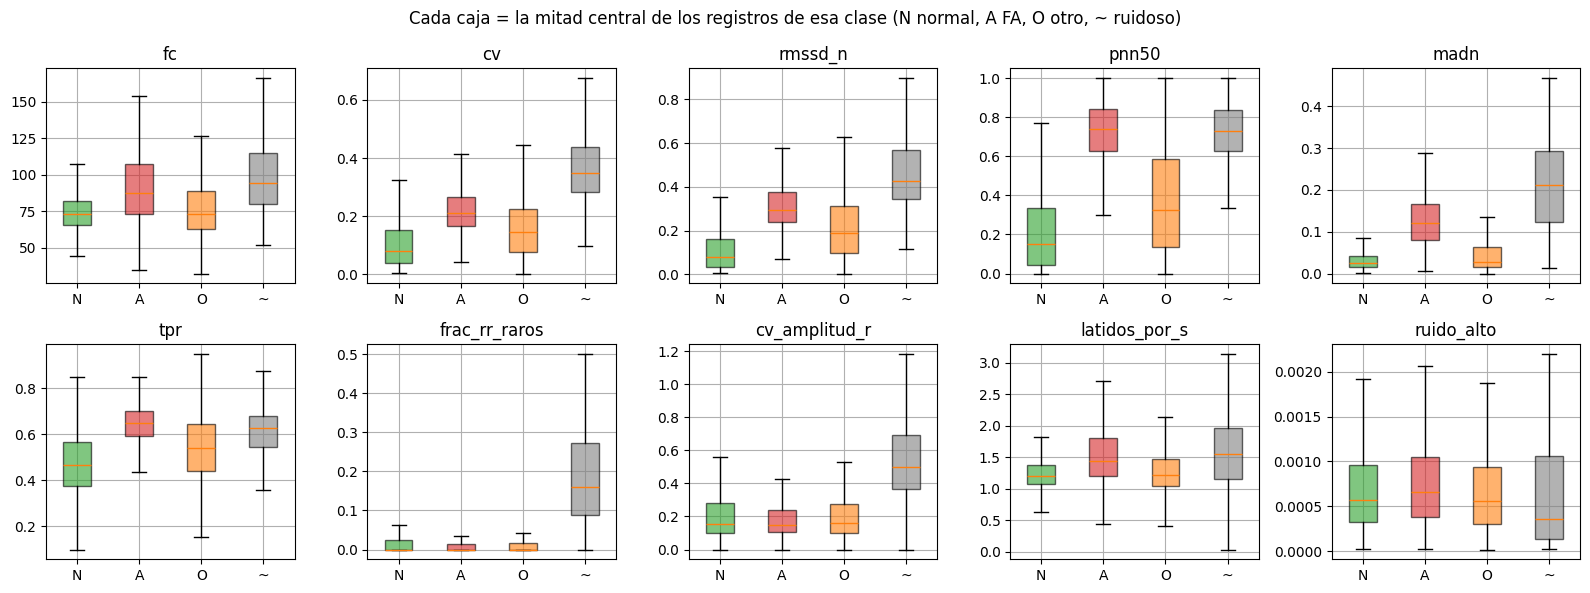

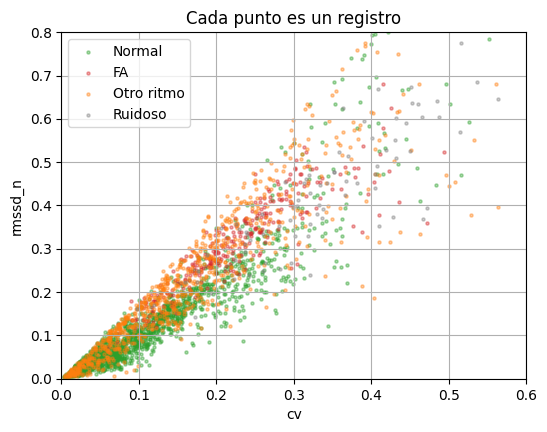

In [8]:
fig, ax = plt.subplots(2, 5, figsize=(16, 6))
colores = ["tab:green", "tab:red", "tab:orange", "gray"]
for eje, col in zip(ax.ravel(), NOMBRES):
    datos = [tabla[tabla.etiqueta == c][col].dropna() for c in CLASES]
    cajas = eje.boxplot(datos, showfliers=False, patch_artist=True)
    for caja, color in zip(cajas["boxes"], colores):
        caja.set_facecolor(color); caja.set_alpha(0.6)
    eje.set_xticks(range(1, 5)); eje.set_xticklabels(CLASES); eje.set_title(col)
plt.suptitle("Cada caja = la mitad central de los registros de esa clase (N normal, A FA, O otro, ~ ruidoso)")
plt.tight_layout(); plt.show()

plt.figure(figsize=(6, 4.5))
muestra = tabla.dropna().sample(min(3000, len(tabla.dropna())), random_state=SEMILLA)
for c, color in zip(CLASES, colores):
    m = muestra[muestra.etiqueta == c]
    plt.scatter(m.cv, m.rmssd_n, s=5, alpha=0.4, color=color, label=NOMBRE_CLASE[c])
plt.xlabel("cv"); plt.ylabel("rmssd_n"); plt.xlim(0, 0.6); plt.ylim(0, 0.8); plt.legend()
plt.title("Cada punto es un registro"); plt.show()

# PARTE C · Modelos

## C.1 Cómo vamos a medir


In [9]:
def evaluar_4_clases(y_real, y_pred, titulo):
    cm = confusion_matrix(y_real, y_pred, labels=CLASES)
    cm_pct = 100 * cm / cm.sum(axis=1, keepdims=True)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm_pct, annot=cm, fmt="d", cmap="Blues", cbar=False, vmin=0, vmax=100,
                xticklabels=[f"dijo {c}" for c in CLASES], yticklabels=[f"real {c}" for c in CLASES])
    plt.grid(False); plt.title(f"{titulo}\n(número = registros · color = % de la fila)"); plt.show()
    f1 = f1_score(y_real, y_pred, labels=CLASES, average=None, zero_division=0)
    res = {f"F1 {c}": round(v, 3) for c, v in zip(CLASES, f1)}
    res["F1 promedio (N, A, O)"] = round(np.mean(f1[:3]), 3)
    return res

def evaluar_fa(y_real, y_pred):
    real, dijo = np.asarray(y_real) == "A", np.asarray(y_pred) == "A"
    vp, fn = np.sum(real & dijo), np.sum(real & ~dijo)
    vn, fp = np.sum(~real & ~dijo), np.sum(~real & dijo)
    return {"FA Se %": round(100 * vp / (vp + fn), 1), "FA Sp %": round(100 * vn / (vn + fp), 1),
            "FA PPV %": round(100 * vp / (vp + fp), 1) if vp + fp else 0.0}

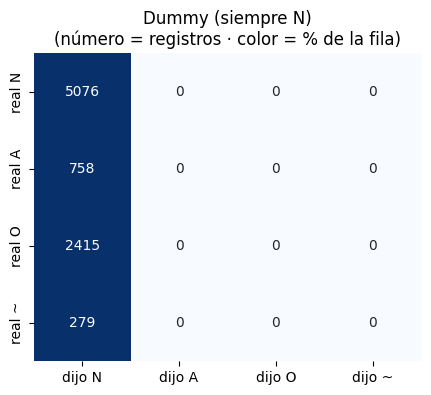

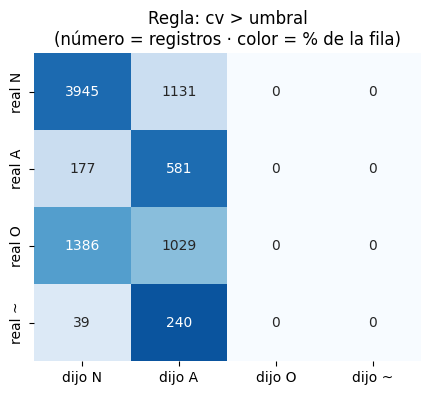

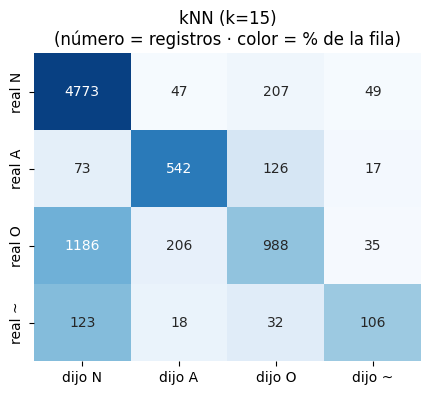

,F1 N,F1 A,F1 O,F1 ~,"F1 promedio (N, A, O)",FA Se %,FA Sp %,FA PPV %
Dummy (siempre N),0.746,0.000,0.000,0.000,0.249,0.0,100.0,0.0
Regla: cv > umbral,0.743,0.311,0.000,0.000,0.351,76.6,69.1,19.5
kNN (k=15),0.850,0.690,0.524,0.436,0.688,71.5,96.5,66.7


In [10]:
class ReglaUmbral:
    # Dice "A" si cv > umbral y "N" si no. Elige el umbral que da mejor F1 de FA en entrenamiento.
    def fit(self, X, y):
        cv = X[:, NOMBRES.index("cv")]
        es_fa = np.asarray(y) == "A"
        candidatos = np.quantile(cv, np.linspace(0.01, 0.99, 99))
        self.umbral = max(candidatos, key=lambda u: f1_score(es_fa, cv > u, zero_division=0))
        return self
    def predict(self, X):
        return np.where(X[:, NOMBRES.index("cv")] > self.umbral, "A", "N")
    def get_params(self, deep=True):
        return {}

# Rellenamos los NaN con la mediana de cada columna
X = tabla[NOMBRES].fillna(tabla[NOMBRES].median()).to_numpy()
y = tabla.etiqueta.to_numpy()
grupos = StratifiedKFold(n_splits=N_GRUPOS, shuffle=True, random_state=SEMILLA)

modelos = {
    "Dummy (siempre N)": DummyClassifier(strategy="most_frequent"),
    "Regla: cv > umbral": ReglaUmbral(),
    f"kNN (k={K_VECINOS})": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=K_VECINOS)),
}
predicciones, resultados = {}, {}
for nombre, modelo in modelos.items():
    if isinstance(modelo, ReglaUmbral):
        pred = np.empty(len(y), dtype=object)
        for entrena, prueba in grupos.split(X, y):
            pred[prueba] = ReglaUmbral().fit(X[entrena], y[entrena]).predict(X[prueba])
    else:
        pred = cross_val_predict(modelo, X, y, cv=grupos)
    predicciones[nombre] = pred
    resultados[nombre] = {**evaluar_4_clases(y, pred, nombre), **evaluar_fa(y, pred)}
display(pd.DataFrame(resultados).T)

## ¿Qué k conviene?

,k,F1 N,F1 A,F1 O,F1 ~,"F1 promedio (N, A, O)"
0,1,0.797,0.606,0.514,0.365,0.639
1,3,0.834,0.611,0.542,0.403,0.662
2,5,0.843,0.655,0.538,0.440,0.679
3,9,0.847,0.665,0.530,0.412,0.680
4,15,0.850,0.690,0.524,0.436,0.688
5,25,0.847,0.682,0.502,0.433,0.677
6,41,0.845,0.678,0.489,0.452,0.671


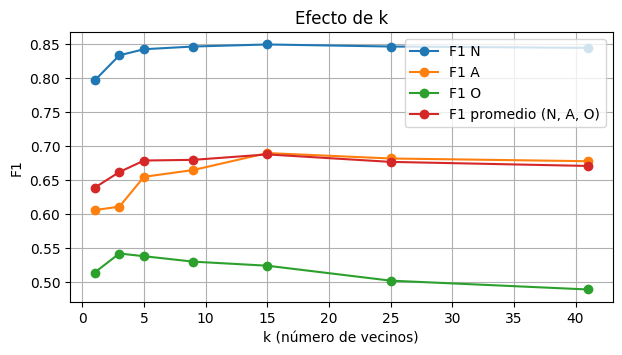

In [11]:
filas = []
for k in [1, 3, 5, 9, 15, 25, 41]:
    pred = cross_val_predict(make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k)), X, y, cv=grupos)
    f1 = f1_score(y, pred, labels=CLASES, average=None, zero_division=0)
    filas.append({"k": k, **{f"F1 {c}": round(v, 3) for c, v in zip(CLASES, f1)},
                  "F1 promedio (N, A, O)": round(np.mean(f1[:3]), 3)})
tabla_k = pd.DataFrame(filas)
display(tabla_k)
plt.figure(figsize=(7, 3.5))
for col in ["F1 N", "F1 A", "F1 O", "F1 promedio (N, A, O)"]:
    plt.plot(tabla_k.k, tabla_k[col], "o-", label=col)
plt.xlabel("k (número de vecinos)"); plt.ylabel("F1"); plt.legend(); plt.title("Efecto de k")
plt.show()

## ¿Qué aportan las medidas de calidad?

Comparar el kNN usando solo las medidas de R–R contra usarlas junto con las de calidad de señal.

In [12]:
filas = []
for nombre, cols in [("solo R–R", NOMBRES_RR), ("solo calidad", NOMBRES_CALIDAD), ("R–R + calidad", NOMBRES)]:
    Xs = tabla[cols].fillna(tabla[cols].median()).to_numpy()
    pred = cross_val_predict(make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=K_VECINOS)),
                             Xs, y, cv=grupos)
    f1 = f1_score(y, pred, labels=CLASES, average=None, zero_division=0)
    filas.append({"medidas": nombre, **{f"F1 {c}": round(v, 3) for c, v in zip(CLASES, f1)},
                  "F1 promedio (N, A, O)": round(np.mean(f1[:3]), 3)})
display(pd.DataFrame(filas))

,medidas,F1 N,F1 A,F1 O,F1 ~,"F1 promedio (N, A, O)"
0,solo R–R,0.842,0.651,0.510,0.378,0.667
1,solo calidad,0.766,0.240,0.243,0.358,0.416
2,R–R + calidad,0.850,0.690,0.524,0.436,0.688


## ¿Dónde se equivoca? Ver los errores

Graficar algunos registros de FA que el kNN no detectó.

FA no detectadas: 216 de 758
¿Qué dijo el modelo en esos casos? {'O': 126, 'N': 73, '~': 17}


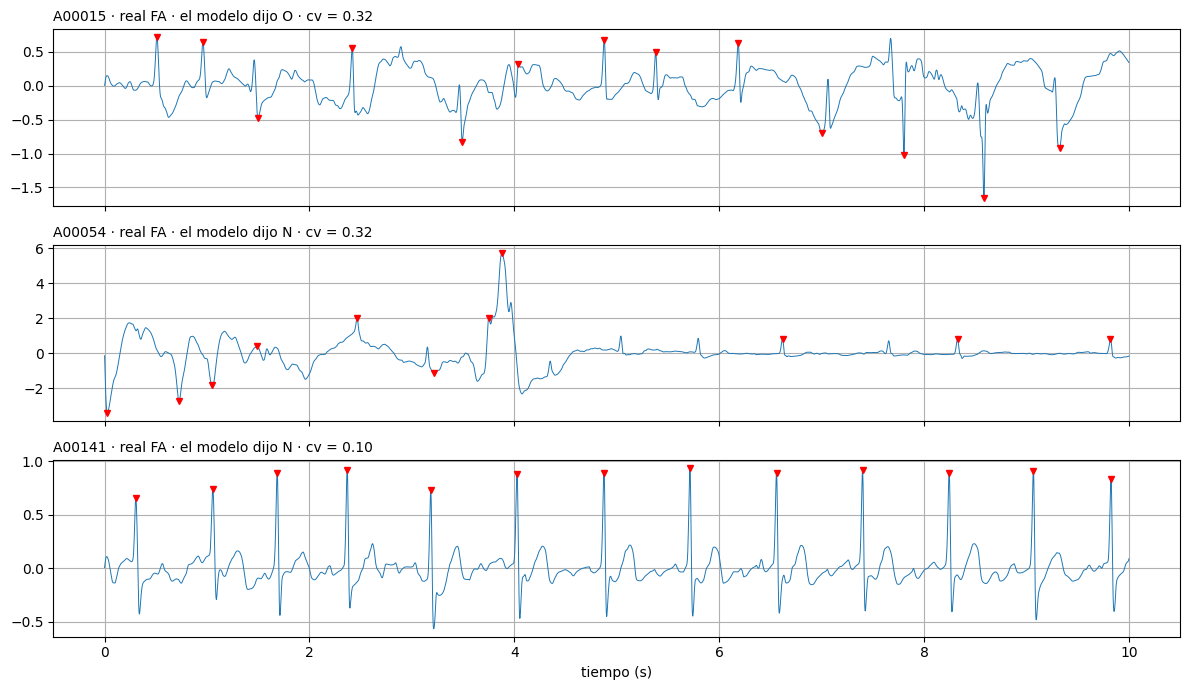

In [13]:
pred_knn = predicciones[f"kNN (k={K_VECINOS})"]
fallos = tabla[(tabla.etiqueta == "A") & (pred_knn != "A")]
print(f"FA no detectadas: {len(fallos)} de {(tabla.etiqueta == 'A').sum()}")
print("¿Qué dijo el modelo en esos casos?", dict(Counter(pred_knn[fallos.index])))

fig, ax = plt.subplots(3, 1, figsize=(12, 7), sharex=True)
for eje, (_, fila) in zip(ax, fallos.head(3).iterrows()):
    x, fs = ec.leer_senal_cinc2017(cinc.ruta[fila.name])
    x = ec.remuestrear(x, fs, ec.FS)
    limpia = ec.filtrar(x, ec.FS)
    r = ec.detectar_picos_r(x, ec.FS)
    n = min(len(limpia), 10 * ec.FS)
    eje.plot(np.arange(n) / ec.FS, limpia[:n], lw=0.7)
    eje.plot(r[r < n] / ec.FS, limpia[r[r < n]], "rv", ms=5)
    eje.set_title(f"{fila.registro} · real FA · el modelo dijo {pred_knn[fila.name]} · cv = {fila.cv:.2f}",
                  loc="left", fontsize=10)
ax[-1].set_xlabel("tiempo (s)")
plt.tight_layout(); plt.show()



## Resumen final

In [14]:
display(pd.DataFrame(resultados).T)

,F1 N,F1 A,F1 O,F1 ~,"F1 promedio (N, A, O)",FA Se %,FA Sp %,FA PPV %
Dummy (siempre N),0.746,0.000,0.000,0.000,0.249,0.0,100.0,0.0
Regla: cv > umbral,0.743,0.311,0.000,0.000,0.351,76.6,69.1,19.5
kNN (k=15),0.850,0.690,0.524,0.436,0.688,71.5,96.5,66.7


In [15]:
import os, joblib

encontrado = False

# 1. Buscar modelos de Scikit-learn / XGBoost / LightGBM en memoria
for nombre, obj in list(locals().items()):
    if hasattr(obj, 'fit') and hasattr(obj, 'predict') and not isinstance(obj, type):
        archivo = f"{nombre}.pkl"
        joblib.dump(obj, archivo)
        peso_kb = os.path.getsize(archivo) / 1024
        print(f"Modelo encontrado -> '{nombre}' ({type(obj).__name__}): {peso_kb:.2f} KB ({peso_kb/1024:.2f} MB)")
        encontrado = True

# 2. Buscar modelos de Keras / TensorFlow en memoria
for nombre, obj in list(locals().items()):
    if 'keras' in str(type(obj)).lower() and hasattr(obj, 'save'):
        import tensorflow as tf
        converter = tf.lite.TFLiteConverter.from_keras_model(obj)
        converter.optimizations = [tf.lite.Optimize.DEFAULT]
        tflite_model = converter.convert()
        archivo = f"{nombre}.tflite"
        with open(archivo, 'wb') as f:
            f.write(tflite_model)
        peso_kb = os.path.getsize(archivo) / 1024
        print(f"Red neuronal encontrada -> '{nombre}' (TFLite): {peso_kb:.2f} KB ({peso_kb/1024:.2f} MB)")
        encontrado = True

if not encontrado:
    print("No hay un modelo guardado en variable global (probablemente está dentro de una función, como en el notebook anterior).")

Modelo encontrado -> 'modelo' (Pipeline): 0.46 KB (0.00 MB)


In [16]:
import sys
sys.path.append('/kaggle/input/tu-carpeta-subida')

In [17]:
import joblib, os

knn_completo = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=K_VECINOS))
knn_completo.fit(X, y)

joblib.dump(knn_completo, 'cinc2017_knn.pkl')
peso_kb = os.path.getsize('cinc2017_knn.pkl') / 1024
print(f"Peso archivo .pkl (float64): {peso_kb:.2f} KB")
print(f"Peso estimado en Arduino/ESP32 (float32): {(X.size * 4 + len(y)) / 1024:.2f} KB")

Peso archivo .pkl (float64): 1563.86 KB
Peso estimado en Arduino/ESP32 (float32): 341.45 KB
